<a href="https://colab.research.google.com/github/tkach3nkoo/MN/blob/main/%D0%9B%D0%A05_%D0%A2%D0%BA%D0%B0%D1%87%D0%B5%D0%BD%D0%BA%D0%BE_%D0%B3%D1%80%D1%83%D0%BF%D0%B0_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [1]:
# Імпортуйте необхідні бібліотеки
import sys
import subprocess
import importlib.util
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

np.random.seed(42)
torch.manual_seed(42)
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 4)
print('Бібліотеки імпортовано.')

Бібліотеки імпортовано.


In [2]:
# Завантажте датасет з Kaggle
if importlib.util.find_spec('kagglehub') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'kagglehub'])
import kagglehub

dataset_dir = Path(kagglehub.dataset_download(
    'yug201/daily-climate-time-series-data-delhi-india'
))
csv_files = sorted(dataset_dir.rglob('*.csv'))
if not csv_files:
    raise FileNotFoundError(f'CSV-файлів немає у {dataset_dir}')
print('Завантажено:', ', '.join(p.name for p in csv_files))

Using Colab cache for faster access to the 'daily-climate-time-series-data-delhi-india' dataset.
Завантажено: kaggel_weather_2013_to_2024.csv


In [3]:
# Зчитайте датасет у DataFrame та перегляньте дані
csv_path = next((p for p in csv_files if '2013' in p.stem and '2024' in p.stem), csv_files[0])
df = pd.read_csv(csv_path, low_memory=False)
print('Файл:', csv_path.name)
display(df.head())
print('Розмір:', df.shape)
display(df.describe(include='all').T)

Файл: kaggel_weather_2013_to_2024.csv


,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


Розмір: (3557, 29)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,3557.0,NaN,NaN,NaN,1778.0,1026.961781,0.0,889.0,1778.0,2667.0,3556.0
DATE,3557,3556,5/1/2022,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tempmax,3557.0,NaN,NaN,NaN,31.367501,7.073934,9.1,26.4,33.0,36.0,47.9
tempmin,3557.0,NaN,NaN,NaN,20.076132,7.568531,2.0,13.0,22.0,26.9,34.8
temp,3557.0,NaN,NaN,NaN,25.403374,7.325541,6.5,19.1,27.7,31.0,39.5
feelslikemax,3557.0,NaN,NaN,NaN,34.28018,9.651743,7.9,26.3,35.4,42.7,57.7
feelslikemin,3557.0,NaN,NaN,NaN,20.938769,9.004827,0.3,13.0,22.0,28.0,41.1
feelslike,3557.0,NaN,NaN,NaN,27.306803,9.301636,5.7,19.1,28.4,35.4,47.0
humidity,3557.0,NaN,NaN,NaN,63.75544,18.129251,16.1,53.0,65.8,76.9,99.3
precip,3557.0,NaN,NaN,NaN,2.459033,10.636255,0.0,0.0,0.0,0.0,203.047


Підготовка даних

In [4]:
# Виконайте попередню обробку даних:
# - DATE -> datetime
# - сортування за датою
# - видалення зайвих колонок
# - встановлення DATE як індексу

df.columns = df.columns.str.strip()
date_candidates = [c for c in df.columns if c.lower() in ('date', 'datetime', 'day', 'time', 'timestamp')]
if not date_candidates:
    raise ValueError(f'Не знайдено колонку з датою: {df.columns.tolist()}')
date_col = date_candidates[0]
df[date_col] = pd.to_datetime(df[date_col], errors='coerce', dayfirst=False)
df = df.dropna(subset=[date_col]).drop_duplicates(subset=[date_col], keep='last')
df = df.sort_values(date_col).set_index(date_col)
df.index.name = 'DATE'
df = df.loc[:, ~df.columns.str.lower().str.startswith('unnamed')]

# Знаходимо колонку температури незалежно від регістру її назви.
priority = ('temp', 'meantemp', 'tavg', 'tmean', 'avgtemp', 'temperature',
            'temperature_2m_mean', 'temperature_c', 'avg_temperature',
            'mean_temperature', 'temperature_2m', 'temp_avg')
col_key = lambda c: ''.join(ch for ch in str(c).lower() if ch.isalnum())
by_key = {col_key(c): c for c in df.columns}
temp_col = next((by_key[col_key(name)] for name in priority if col_key(name) in by_key), None)
if temp_col is None:
    candidates = [c for c in df.columns if 'temp' in c.lower() and
                  not any(w in c.lower() for w in ('min', 'max', 'dew', 'feels'))]
    temp_col = candidates[0] if candidates else None
if temp_col is None:
    raise ValueError(f'Не знайдено колонку температури: {df.columns.tolist()}')

df[temp_col] = pd.to_numeric(df[temp_col], errors='coerce')
df = df.loc[~df.index.isna()]
df = df.asfreq('D')
df[temp_col] = df[temp_col].ffill().bfill()
print('Колонка температури:', temp_col)
print('Період:', df.index.min().date(), '—', df.index.max().date())
display(df.head())

Колонка температури: temp
Період: 2013-04-14 — 2024-11-30


,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,precipcover,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
DATE,,,,,,,,,,,,,,,,,,,,,
2013-04-14,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,100.0,4.17,...,13.0,15.0,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
2013-04-15,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,0.0,0.00,...,13.0,16.0,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2013-04-16,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,0.0,0.00,...,13.0,16.0,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
2013-04-17,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,0.0,0.00,...,13.0,16.0,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
2013-04-18,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,0.0,0.00,...,13.0,16.0,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


In [5]:
# Перегляньте інформацію про структуру датасету
df.info()
display(df.describe().T)

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4249 entries, 2013-04-14 to 2024-11-30
Freq: D
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   tempmax                3556 non-null   float64
 1   tempmin                3556 non-null   float64
 2   temp                   4249 non-null   float64
 3   feelslikemax           3556 non-null   float64
 4   feelslikemin           3556 non-null   float64
 5   feelslike              3556 non-null   float64
 6   humidity               3556 non-null   float64
 7   precip                 3556 non-null   float64
 8   precipprob             3556 non-null   float64
 9   precipcover            3556 non-null   float64
 10  windspeed              3556 non-null   float64
 11  sealevelpressure       3556 non-null   float64
 12  conditions             3556 non-null   object 
 13  Year                   3556 non-null   float64
 14  month                  3556 no

,count,mean,std,min,25%,50%,75%,max
tempmax,3556.0,31.365073,7.073447,9.100000,26.400000,32.950000,36.000000,47.900000
tempmin,3556.0,20.073847,7.568369,2.000000,13.000000,22.000000,26.900000,34.800000
temp,4249.0,25.463733,7.211625,6.500000,19.400000,27.700000,31.100000,39.500000
feelslikemax,3556.0,34.277925,9.652163,7.900000,26.300000,35.350000,42.700000,57.700000
feelslikemin,3556.0,20.936699,9.005246,0.300000,13.000000,22.000000,28.000000,41.100000
feelslike,3556.0,27.304921,9.302266,5.700000,19.100000,28.400000,35.400000,47.000000
humidity,3556.0,63.764258,18.124170,16.100000,53.000000,65.800000,76.900000,99.300000
precip,3556.0,2.459725,10.637671,0.000000,0.000000,0.000000,0.000000,203.047000
precipprob,3556.0,23.143982,42.181212,0.000000,0.000000,0.000000,0.000000,100.000000
precipcover,3556.0,1.783597,4.009908,0.000000,0.000000,0.000000,0.000000,45.830000


In [6]:
# Перевірте наявність пропущених значень
print('Кількість пропусків у колонках:')
display(df.isna().sum().to_frame('Пропуски'))
print('Пропуски температури після обробки:', df[temp_col].isna().sum())

Кількість пропусків у колонках:


,Пропуски
tempmax,693
tempmin,693
temp,0
feelslikemax,693
feelslikemin,693
feelslike,693
humidity,693
precip,693
precipprob,693
precipcover,693


Пропуски температури після обробки: 0


Графік температури

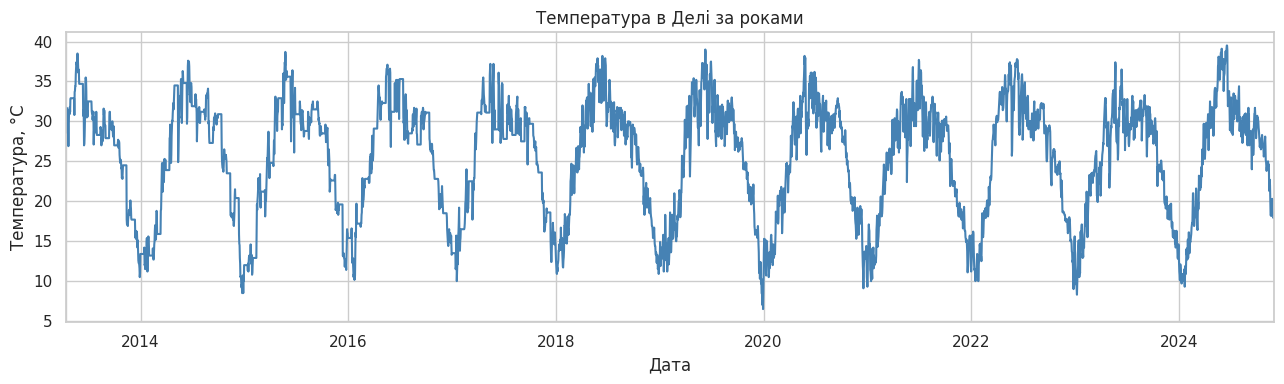

In [7]:
# Побудуйте графік зміни температури у часі
ax = df[temp_col].plot(figsize=(13, 4), color='steelblue')
ax.set(title='Температура в Делі за роками', xlabel='Дата', ylabel='Температура, °C')
plt.tight_layout()
plt.show()

Ковзне середнє

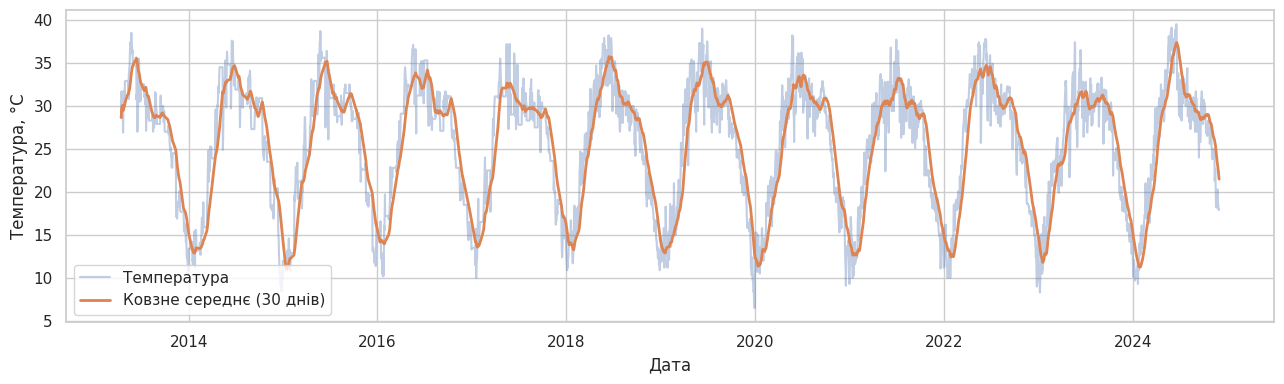

In [8]:
# Обчисліть та візуалізуйте ковзне середнє температури
rolling_30 = df[temp_col].rolling(window=30, min_periods=1).mean()
plt.figure(figsize=(13, 4))
plt.plot(df.index, df[temp_col], label='Температура', alpha=0.35)
plt.plot(rolling_30.index, rolling_30, label='Ковзне середнє (30 днів)', linewidth=2)
plt.xlabel('Дата')
plt.ylabel('Температура, °C')
plt.legend()
plt.tight_layout()
plt.show()

Розподіл температури

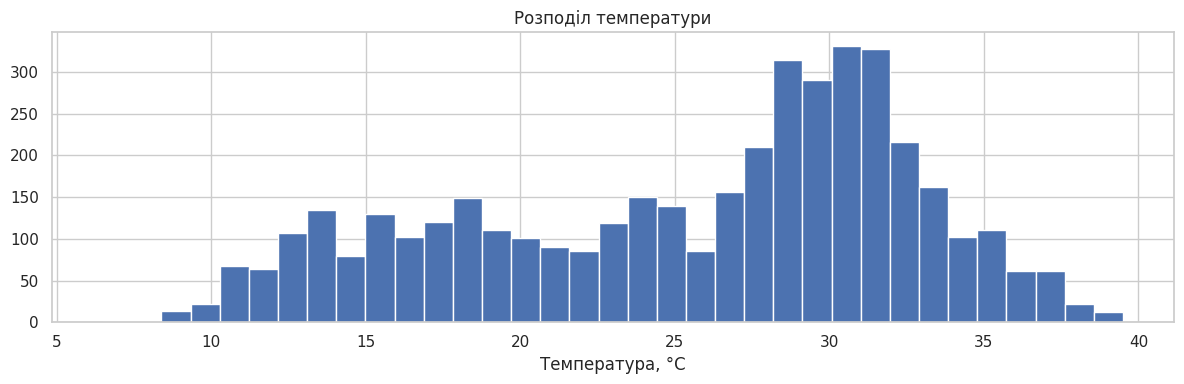

In [9]:
# Побудуйте гістограму розподілу температури
plt.hist(df[temp_col].dropna(), bins=35, edgecolor='white')
plt.title('Розподіл температури')
plt.xlabel('Температура, °C')
plt.tight_layout()
plt.show()

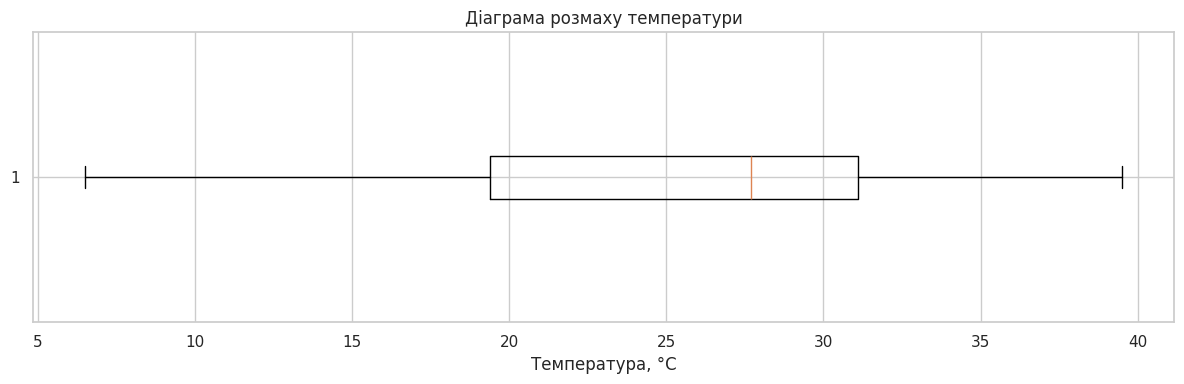

Кількість потенційних викидів: 0


In [10]:
# Побудуйте boxplot температури для аналізу викидів
plt.boxplot(df[temp_col].dropna(), vert=False)
plt.title('Діаграма розмаху температури')
plt.xlabel('Температура, °C')
plt.tight_layout()
plt.show()
q1, q3 = df[temp_col].quantile([0.25, 0.75])
iqr = q3 - q1
outliers = df[(df[temp_col] < q1 - 1.5 * iqr) | (df[temp_col] > q3 + 1.5 * iqr)]
print('Кількість потенційних викидів:', len(outliers))

Аналіз автокореляції
ACF

PACF

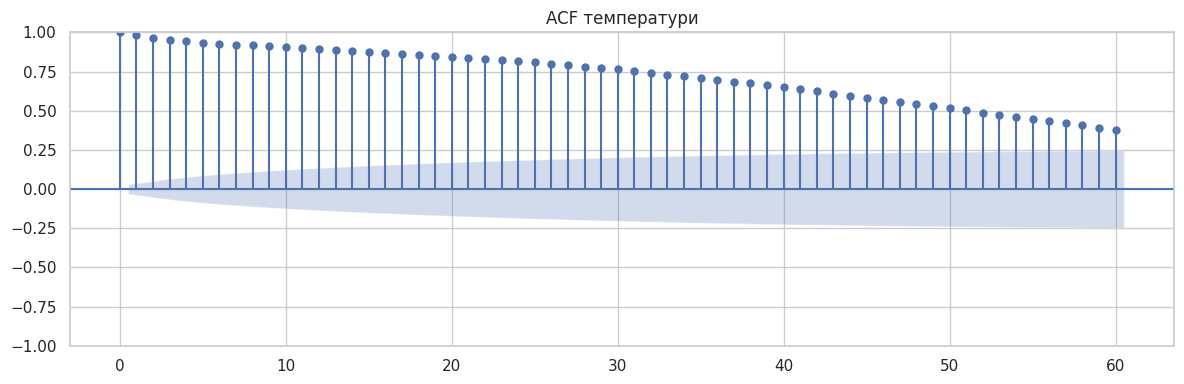

In [11]:
# Побудуйте графік автокореляційної функції (ACF)
fig, ax = plt.subplots(figsize=(12, 4))
plot_acf(df[temp_col].dropna(), lags=60, ax=ax)
plt.title('ACF температури')
plt.tight_layout()
plt.show()

Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

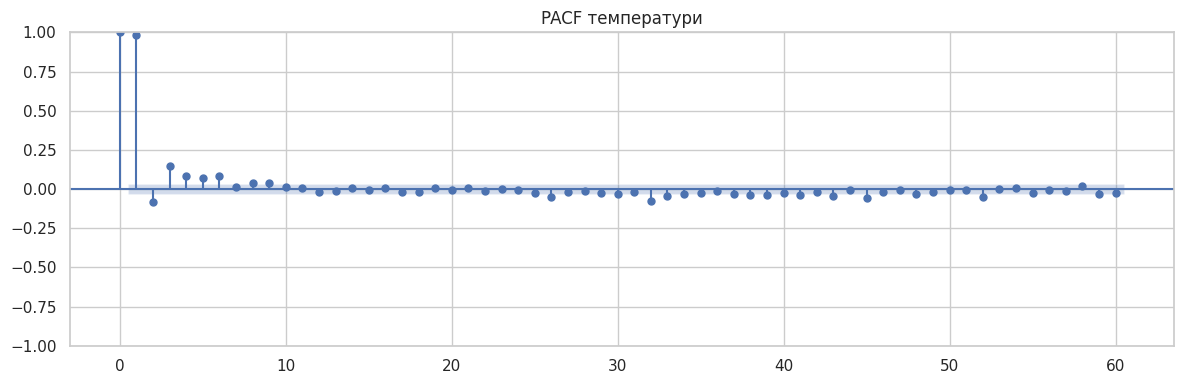

In [12]:
# Побудуйте графік часткової автокореляційної функції (PACF)
fig, ax = plt.subplots(figsize=(12, 4))
plot_pacf(df[temp_col].dropna(), lags=60, method='ywm', ax=ax)
plt.title('PACF температури')
plt.tight_layout()
plt.show()

Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

Навчальна вибірка: 3399 (2013-04-14 — 2022-08-03)
Тестова вибірка: 850 (2022-08-04 — 2024-11-30)


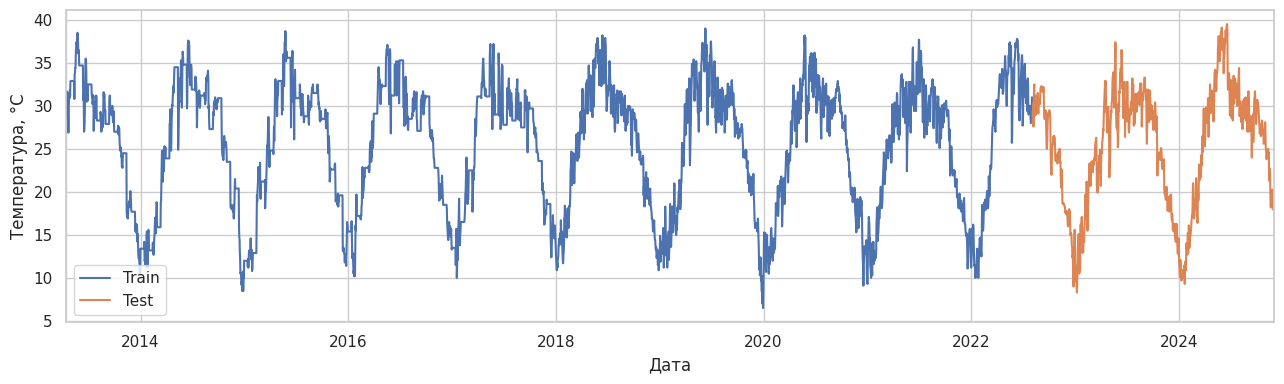

In [13]:
# Сформуйте цільовий часовий ряд та розділіть його на train/test у часовому порядку
series = df[temp_col].dropna().astype('float64').asfreq('D')
train_size = int(len(series) * 0.8)
train = series.iloc[:train_size]
test = series.iloc[train_size:]
assert len(train) > 60 and len(test) > 0
print(f'Навчальна вибірка: {len(train)} ({train.index[0].date()} — {train.index[-1].date()})')
print(f'Тестова вибірка: {len(test)} ({test.index[0].date()} — {test.index[-1].date()})')
ax = train.plot(label='Train', figsize=(13, 4))
test.plot(ax=ax, label='Test')
ax.set(xlabel='Дата', ylabel='Температура, °C')
plt.legend()
plt.tight_layout()
plt.show()

ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [14]:
# Побудуйте та навчіть модель ARIMA. Отримайте прогноз для тестової вибірки
arima_model = ARIMA(train, order=(5, 1, 0)).fit()
arima_forecast = pd.Series(arima_model.forecast(steps=len(test)).to_numpy(),
                           index=test.index, name='ARIMA')
display(arima_forecast.head())

,ARIMA
DATE,
2022-08-04,30.404310
2022-08-05,30.189192
2022-08-06,30.096439
2022-08-07,30.063820
2022-08-08,30.142405


In [15]:
# Виведіть статистичний звіт навченої ARIMA-моделі
print(arima_model.summary())

                               SARIMAX Results                                
Dep. Variable:                   temp   No. Observations:                 3399
Model:                 ARIMA(5, 1, 0)   Log Likelihood               -5606.986
Date:                Sat, 17 Oct 2026   AIC                          11225.972
Time:                        21:03:26   BIC                          11262.757
Sample:                    04-14-2013   HQIC                         11239.120
                         - 08-03-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0616      0.014      4.479      0.000       0.035       0.089
ar.L2         -0.1716      0.015    -11.742      0.000      -0.200      -0.143
ar.L3         -0.1061      0.015     -6.979      0.0

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

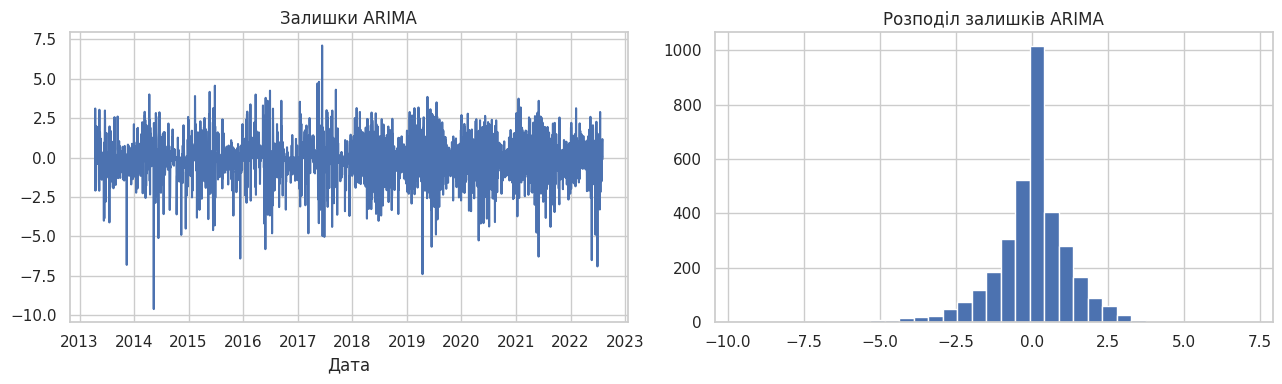

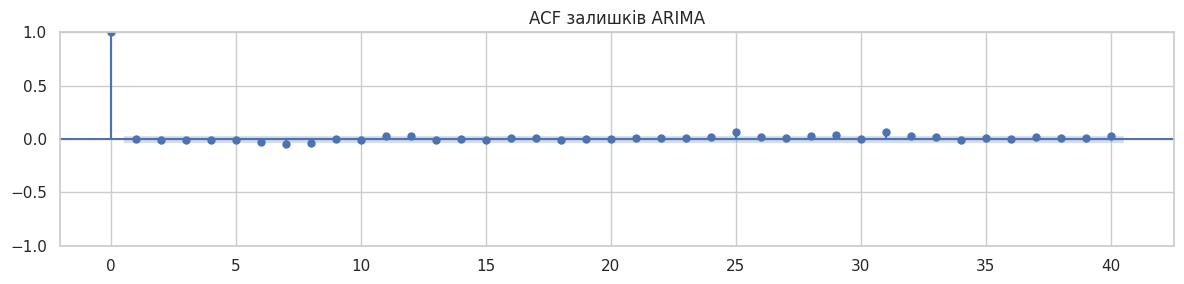

In [16]:
# Проаналізуйте залишки ARIMA-моделі та побудуйте відповідні графіки
residuals = arima_model.resid.iloc[1:]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(residuals)
axes[0].set_title('Залишки ARIMA')
axes[0].set_xlabel('Дата')
axes[1].hist(residuals.dropna(), bins=35, edgecolor="white")
axes[1].set_title('Розподіл залишків ARIMA')
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(12, 3))
plot_acf(residuals.dropna(), lags=40, ax=ax)
plt.title('ACF залишків ARIMA')
plt.tight_layout()
plt.show()

In [17]:
# Реалізуйте MAPE та обчисліть MAE, RMSE, MAPE для ARIMA
def mape(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = np.abs(y_true) > 1e-8
    return float(np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100) if mask.any() else np.nan

def metrics(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'MAPE (%)': mape(y_true, y_pred),
    }

arima_metrics = metrics(test, arima_forecast)
print(pd.Series(arima_metrics).round(3))

MAE          6.239
RMSE         8.459
MAPE (%)    36.050
dtype: float64


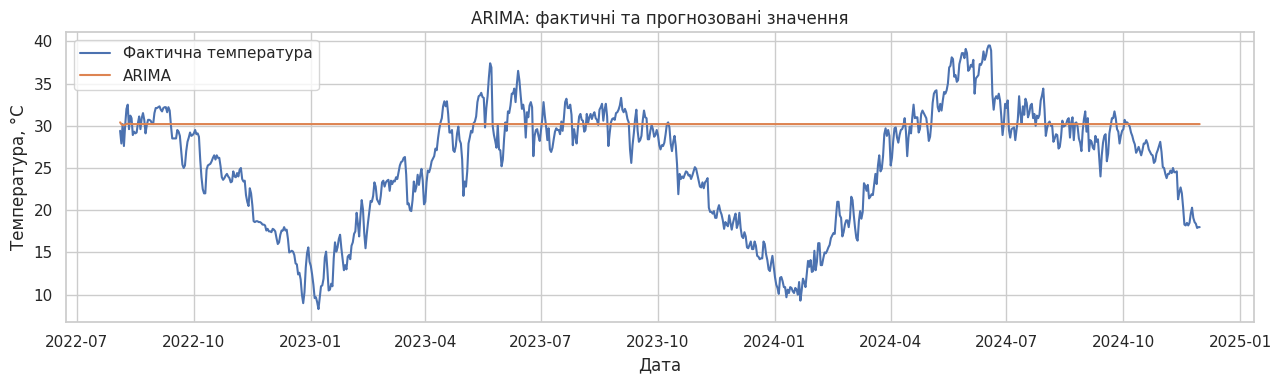

In [18]:
# Візуалізуйте фактичні значення та прогноз ARIMA
plt.figure(figsize=(13, 4))
plt.plot(test.index, test, label='Фактична температура')
plt.plot(arima_forecast.index, arima_forecast, label='ARIMA')
plt.title('ARIMA: фактичні та прогнозовані значення')
plt.xlabel('Дата')
plt.ylabel('Температура, °C')
plt.legend()
plt.tight_layout()
plt.show()

PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [19]:
# Підготуйте дані у форматі, необхідному для Prophet
prophet_train = pd.DataFrame({'ds': train.index, 'y': train.to_numpy()})
prophet_future = pd.DataFrame({'ds': test.index})
display(prophet_train.head())

,ds,y
0,2013-04-14,28.7
1,2013-04-15,28.6
2,2013-04-16,31.7
3,2013-04-17,29.9
4,2013-04-18,30.6


In [20]:
# Створіть та навчіть модель Prophet
if importlib.util.find_spec('prophet') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'prophet'])
from prophet import Prophet

prophet_model = Prophet(yearly_seasonality=True, weekly_seasonality=True,
                        daily_seasonality=False, changepoint_prior_scale=0.05)
prophet_model.fit(prophet_train)
print('Prophet навчено.')

Prophet навчено.


Прогноз

In [21]:
# Побудуйте прогноз Prophet для тестового періоду
prophet_result = prophet_model.predict(prophet_future)
prophet_forecast = pd.Series(prophet_result['yhat'].to_numpy(),
                             index=test.index, name='Prophet')
display(prophet_result[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].head())

,ds,yhat,yhat_lower,yhat_upper
0,2022-08-04,30.087638,27.350318,32.761037
1,2022-08-05,30.130808,27.677781,32.931584
2,2022-08-06,30.156024,27.442627,32.827223
3,2022-08-07,30.189492,27.512541,32.766961
4,2022-08-08,30.329402,27.583632,33.050685


In [22]:
# Обчисліть MAE, RMSE, MAPE для Prophet
prophet_metrics = metrics(test, prophet_forecast)
print(pd.Series(prophet_metrics).round(3))

MAE         2.046
RMSE        2.615
MAPE (%)    9.261
dtype: float64


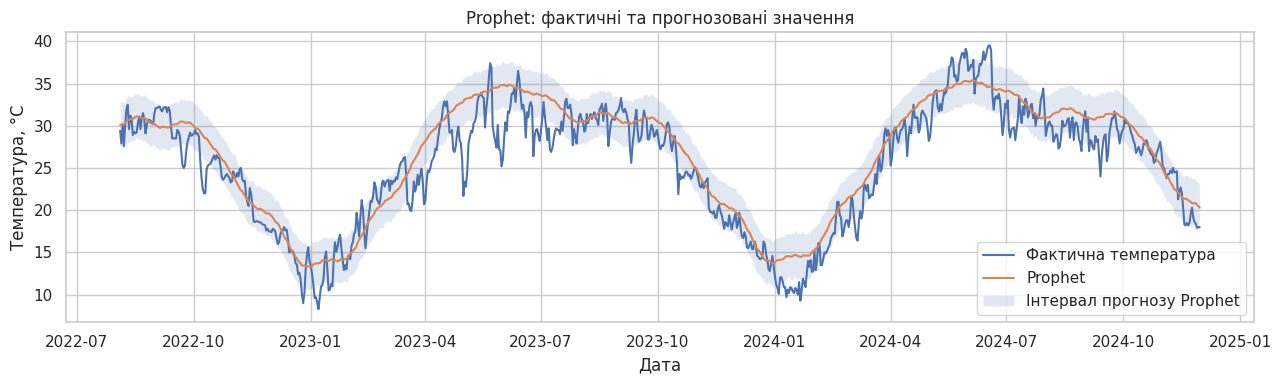

In [23]:
# Візуалізуйте фактичні значення та прогноз Prophet
plt.figure(figsize=(13, 4))
plt.plot(test.index, test, label='Фактична температура')
plt.plot(prophet_forecast.index, prophet_forecast, label='Prophet')
plt.fill_between(test.index,
                 prophet_result['yhat_lower'].to_numpy(),
                 prophet_result['yhat_upper'].to_numpy(),
                 alpha=0.16, label='Інтервал прогнозу Prophet')
plt.title('Prophet: фактичні та прогнозовані значення')
plt.xlabel('Дата')
plt.ylabel('Температура, °C')
plt.legend()
plt.tight_layout()
plt.show()

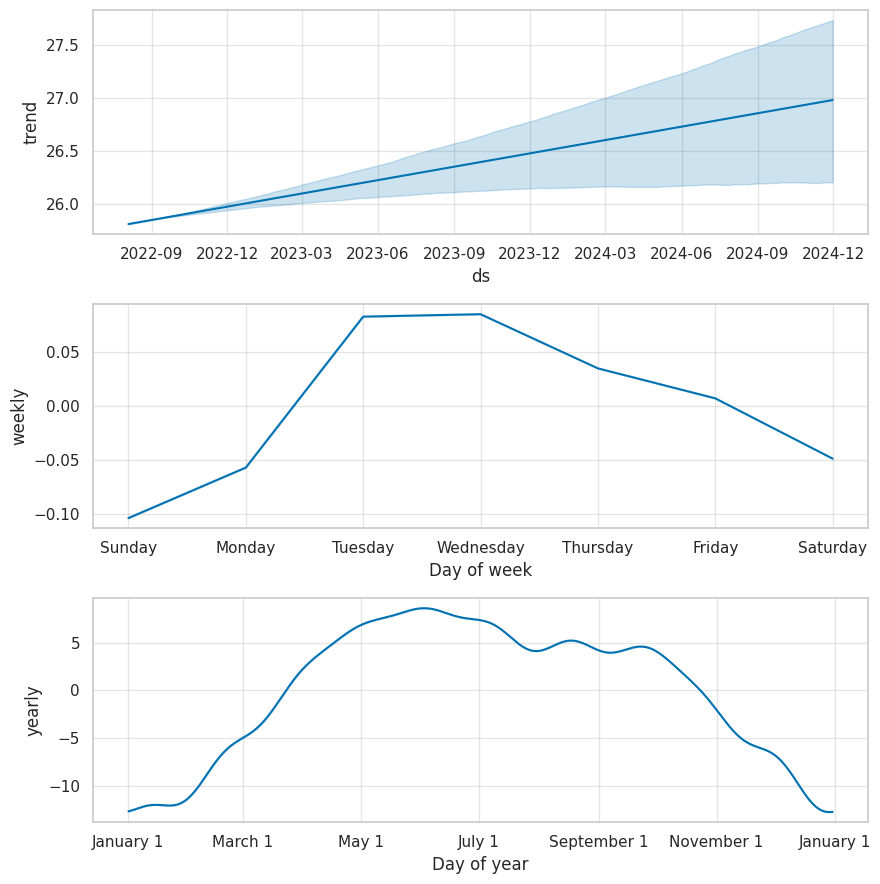

In [24]:
# Побудуйте компоненти моделі Prophet
fig = prophet_model.plot_components(prophet_result)
plt.show()

ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [25]:
# Масштабуйте часовий ряд та сформуйте послідовності для LSTM
window = 30
scaler = MinMaxScaler()
scaler.fit(train.to_numpy().reshape(-1, 1))  # масштабування тільки за train
scaled_train = scaler.transform(train.to_numpy().reshape(-1, 1)).flatten().astype('float32')
scaled_all = scaler.transform(series.to_numpy().reshape(-1, 1)).flatten().astype('float32')

def make_sequences(values, length=30):
    x = np.stack([values[i-length:i] for i in range(length, len(values))])
    y = values[length:]
    return x[:, :, np.newaxis], y[:, np.newaxis]

X_all, y_all = make_sequences(scaled_all, window)
print('Розмір усіх послідовностей:', X_all.shape, y_all.shape)

Розмір усіх послідовностей: (4219, 30, 1) (4219, 1)


In [26]:
# Розділіть послідовності на тренувальну та тестову вибірки без перемішування
n_train_seq = train_size - window
X_train, y_train = X_all[:n_train_seq], y_all[:n_train_seq]
X_test, y_test = X_all[n_train_seq:], y_all[n_train_seq:]
print('Train:', X_train.shape, y_train.shape)
print('Test:', X_test.shape, y_test.shape)
# X_test використовується для контролю розбиття; сам прогноз формується
# рекурсивно лише на основі train, без доступу до фактичного test.

Train: (3369, 30, 1) (3369, 1)
Test: (850, 30, 1) (850, 1)


In [27]:
# Побудуйте архітектуру LSTM-моделі та скомпілюйте її
class LSTMForecast(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=32, num_layers=1, batch_first=True)
        self.head = nn.Linear(32, 1)

    def forward(self, x):
        output, _ = self.lstm(x)
        return self.head(output[:, -1, :])

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
lstm_model = LSTMForecast().to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(lstm_model.parameters(), lr=0.003)
print('Пристрій:', device)

Пристрій: cuda


Епоха 01: train=0.09215, val=0.02676
Епоха 02: train=0.01431, val=0.00820
Епоха 03: train=0.00668, val=0.00415
Епоха 04: train=0.00445, val=0.00392
Епоха 05: train=0.00387, val=0.00369
Епоха 06: train=0.00360, val=0.00357
Епоха 07: train=0.00353, val=0.00347
Епоха 08: train=0.00353, val=0.00338
Епоха 09: train=0.00349, val=0.00329
Епоха 10: train=0.00337, val=0.00319
Епоха 11: train=0.00324, val=0.00310
Епоха 12: train=0.00314, val=0.00302
Епоха 13: train=0.00306, val=0.00295
Епоха 14: train=0.00300, val=0.00289
Епоха 15: train=0.00294, val=0.00283
Епоха 16: train=0.00289, val=0.00278
Епоха 17: train=0.00284, val=0.00273
Епоха 18: train=0.00279, val=0.00268
Епоха 19: train=0.00274, val=0.00263
Епоха 20: train=0.00269, val=0.00258


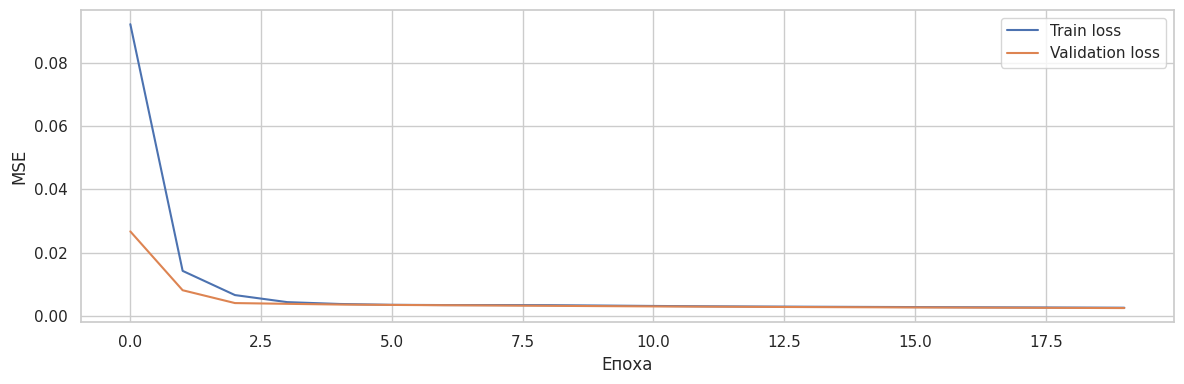

In [28]:
# Навчіть LSTM-модель
# Останні 10% навчальних послідовностей використовуються для early stopping.
cutoff = int(0.9 * len(X_train))
loader = DataLoader(TensorDataset(torch.from_numpy(X_train[:cutoff]),
                                  torch.from_numpy(y_train[:cutoff])),
                    batch_size=64, shuffle=False)
val_x = torch.from_numpy(X_train[cutoff:]).to(device)
val_y = torch.from_numpy(y_train[cutoff:]).to(device)
loss_history, val_history = [], []
best_loss, best_state, patience_count = float('inf'), None, 0
for epoch in range(20):
    lstm_model.train()
    total_loss, batches = 0.0, 0
    for bx, by in loader:
        bx, by = bx.to(device), by.to(device)
        optimizer.zero_grad()
        loss = criterion(lstm_model(bx), by)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        batches += 1
    lstm_model.eval()
    with torch.no_grad():
        val_loss = criterion(lstm_model(val_x), val_y).item()
    loss_history.append(total_loss / batches)
    val_history.append(val_loss)
    if val_loss < best_loss - 1e-5:
        best_loss = val_loss
        best_state = {k: v.detach().cpu().clone() for k, v in lstm_model.state_dict().items()}
        patience_count = 0
    else:
        patience_count += 1
    print(f'Епоха {epoch+1:02d}: train={loss_history[-1]:.5f}, val={val_loss:.5f}')
    if patience_count >= 4:
        break
lstm_model.load_state_dict(best_state)
lstm_model.eval()
plt.plot(loss_history, label='Train loss')
plt.plot(val_history, label='Validation loss')
plt.xlabel('Епоха')
plt.ylabel('MSE')
plt.legend()
plt.tight_layout()
plt.show()

In [29]:
# Виведіть структуру LSTM-моделі
print(lstm_model)
print('Кількість параметрів:', sum(p.numel() for p in lstm_model.parameters()))

LSTMForecast(
  (lstm): LSTM(1, 32, batch_first=True)
  (head): Linear(in_features=32, out_features=1, bias=True)
)
Кількість параметрів: 4513


In [30]:
# Отримайте прогноз LSTM та виконайте зворотне масштабування
# Рекурсивний прогноз: жодне фактичне значення test не використовується.
context = scaled_train[-window:].copy()
preds_scaled = []
lstm_model.eval()
with torch.no_grad():
    for _ in range(len(test)):
        x = torch.from_numpy(context.reshape(1, window, 1)).to(device)
        value = float(lstm_model(x).cpu().item())
        preds_scaled.append(value)
        context = np.concatenate([context[1:], [value]]).astype('float32')
lstm_predictions = scaler.inverse_transform(np.asarray(preds_scaled).reshape(-1, 1)).ravel()
print('Побудовано прогноз на', len(lstm_predictions), 'днів')

Побудовано прогноз на 850 днів


In [31]:
# Сформуйте часові мітки для тестового прогнозу LSTM
lstm_forecast = pd.Series(lstm_predictions, index=test.index, name='LSTM')
display(lstm_forecast.head())

,LSTM
DATE,
2022-08-04,30.263997
2022-08-05,30.401525
2022-08-06,30.501302
2022-08-07,30.580950
2022-08-08,30.650337


In [32]:
# Обчисліть MAE, RMSE, MAPE для LSTM
lstm_metrics = metrics(test, lstm_forecast)
print(pd.Series(lstm_metrics).round(3))

MAE          7.881
RMSE        10.167
MAPE (%)    44.551
dtype: float64


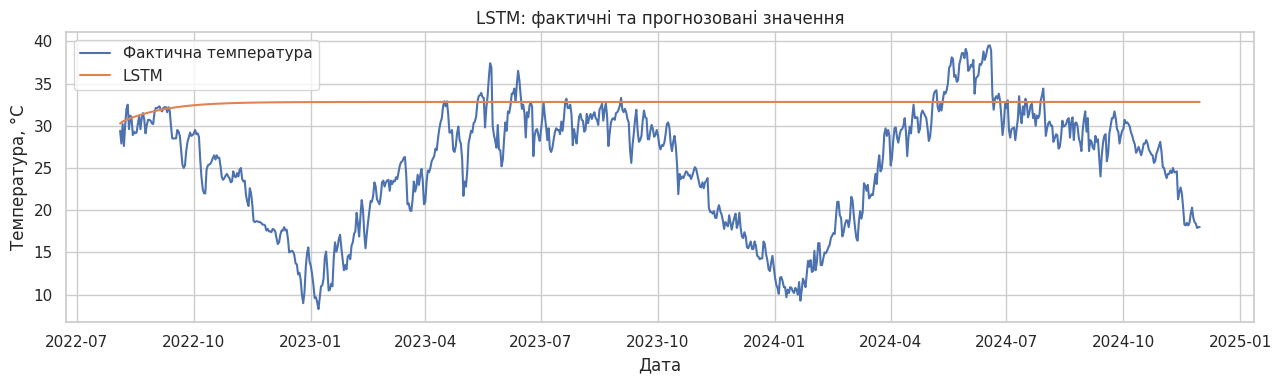

In [33]:
# Візуалізуйте фактичні значення та прогноз LSTM
plt.figure(figsize=(13, 4))
plt.plot(test.index, test, label='Фактична температура')
plt.plot(lstm_forecast.index, lstm_forecast, label='LSTM')
plt.title('LSTM: фактичні та прогнозовані значення')
plt.xlabel('Дата')
plt.ylabel('Температура, °C')
plt.legend()
plt.tight_layout()
plt.show()

Порівняння моделей

,MAE,RMSE,MAPE (%)
Prophet,2.046,2.615,9.261
ARIMA,6.239,8.459,36.050
LSTM,7.881,10.167,44.551


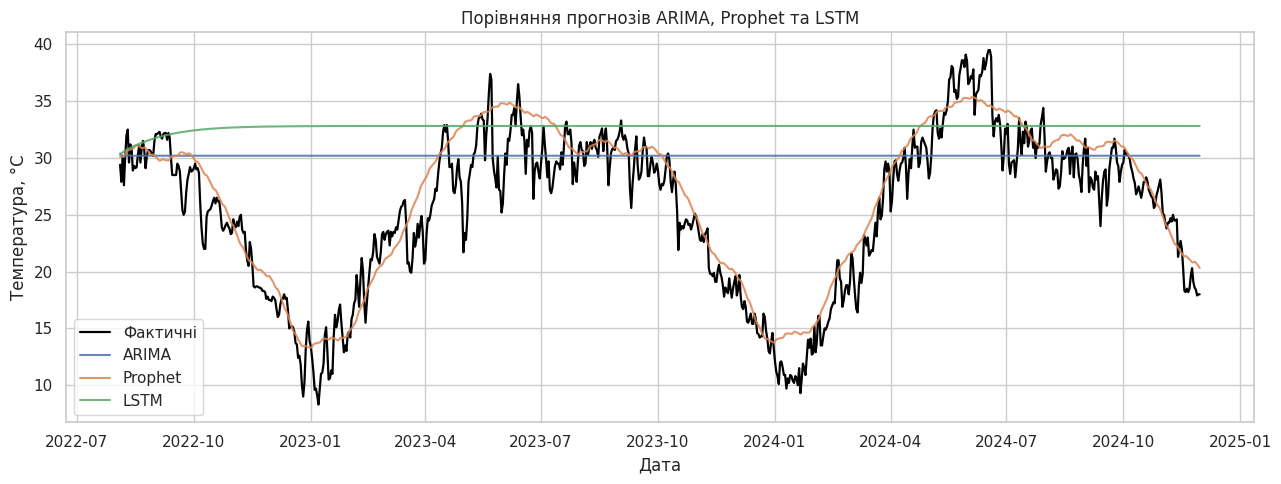

Висновок: виконано попередню обробку та EDA температурного ряду, досліджено ACF і PACF, побудовано ARIMA, Prophet та LSTM.
На однаковому відкладеному тестовому періоді найкраща модель за MAE — Prophet: MAE = 2.046, RMSE = 2.615, MAPE = 9.26%.


In [34]:
# Створіть підсумкову таблицю MAE, RMSE, MAPE для ARIMA, Prophet та LSTM
# Порівняйте моделі за отриманими результатами
results = pd.DataFrame({'ARIMA': arima_metrics, 'Prophet': prophet_metrics,
                        'LSTM': lstm_metrics}).T.sort_values('MAE')
display(results.round(3))

plt.figure(figsize=(13, 5))
plt.plot(test.index, test, label='Фактичні', color='black', linewidth=1.6)
plt.plot(arima_forecast.index, arima_forecast, label='ARIMA', alpha=0.85)
plt.plot(prophet_forecast.index, prophet_forecast, label='Prophet', alpha=0.85)
plt.plot(lstm_forecast.index, lstm_forecast, label='LSTM', alpha=0.85)
plt.title('Порівняння прогнозів ARIMA, Prophet та LSTM')
plt.xlabel('Дата')
plt.ylabel('Температура, °C')
plt.legend()
plt.tight_layout()
plt.show()

winner = results.index[0]
print('Висновок: виконано попередню обробку та EDA температурного ряду, '
      'досліджено ACF і PACF, побудовано ARIMA, Prophet та LSTM.')
print('На однаковому відкладеному тестовому періоді найкраща модель за MAE — '
      f'{winner}: MAE = {results.loc[winner, "MAE"]:.3f}, '
      f'RMSE = {results.loc[winner, "RMSE"]:.3f}, '
      f'MAPE = {results.loc[winner, "MAPE (%)"]:.2f}%.')

## Висновок

Виконано підготовку та дослідницький аналіз часового ряду температури, побудовано ACF і PACF, навчено ARIMA, Prophet та LSTM. Прогнози оцінено на однаковій тестовій вибірці за MAE, RMSE і MAPE. Підсумкова таблиця, графік порівняння та визначення найкращої моделі наведені у попередній комірці.